<a href="https://colab.research.google.com/github/honggi82/Software_application_lecture/blob/main/LSTM_Traffic.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 라이브러리 가져오기

In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from keras.utils import get_file
from keras.models import Sequential
from keras.layers import LSTM, Dense

# 데이터셋 다운로드

In [2]:
# PeMSD7 data
url = 'https://github.com/VeritasYin/STGCN_IJCAI-18/raw/master/dataset/PeMSD7_Full.zip'
data_dir = get_file(origin=url, extract=True)
speeds = pd.read_csv(os.path.join(data_dir, 'PeMSD7_V_228.csv'), header=None).to_numpy()
print(speeds.shape)

29211203/29211203 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
(12672, 228)


# Training, Test 데이터셋 준비

In [3]:
speed = speeds[:, 0] / speeds[:, 0].max()

T = 12
X = []
Y = []
for i in range(len(speed) - T):
  X.append(speed[i:i+T]) # 입력: i ~ i+11번째 값 12개
  Y.append(speed[i+T]) # 정답: i+12번째 값 1개
  X = np.array(X).reshape(-1, T, 1) # (12660, 12, 1)
  Y = np.array(Y) # (12660,)

n = int(len(X) * 0.8)
train_X = X[:n]
test_X = X[n:]
train_Y = Y[:n]
test_Y = Y[n:]
print(train_X.shape, train_Y.shape, test_X.shape, test_Y.shape)

(10128, 12, 1) (10128,) (2532, 12, 1) (2532,)


# 모델 생성

In [4]:
# Model
model = Sequential([ LSTM(64, activation='relu', input_shape=(12, 1)), Dense(1)])
model.compile(loss='mse', optimizer='adam')
model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 64)             │        16,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,961 (66.25 KB)

 Trainable params: 16,961 (66.25 KB)

 Non-trainable params: 0 (0.00 B)

# Training

In [5]:
model.fit(train_X, train_Y, epochs=20, batch_size=64, validation_data=(test_X, test_Y))

Epoch 1/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 6s 19ms/step - loss: 0.0422 - val_loss: 0.0102
Epoch 2/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0060 - val_loss: 0.0067
Epoch 3/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0039 - val_loss: 0.0042
Epoch 4/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0025 - val_loss: 0.0028
Epoch 5/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0020 - val_loss: 0.0024
Epoch 6/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - loss: 0.0018 - val_loss: 0.0024
Epoch 7/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0016 - val_loss: 0.0019
Epoch 8/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0015 - val_loss: 0.0023
Epoch 9/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0014 - val_loss: 0.0018
Epoch 10/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 0.0014 - val_loss: 0.0017
Epoch 11/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0014 - val_loss: 0.0019
Epoch 12/20
159/159 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/ste

# Test

80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0015
Test Loss:  0.001506468397565186
80/80 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step


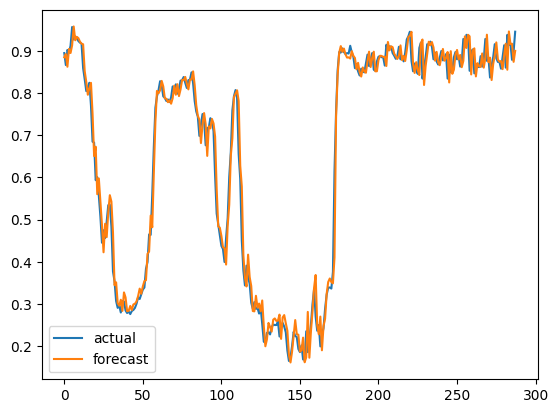

In [6]:
loss = model.evaluate(test_X, test_Y)
print('Test Loss: ', loss)
pred_Y = model.predict(test_X)
plt.plot(test_Y[:288], label='actual')
plt.plot(pred_Y[:288], label='forecast')
plt.legend()
plt.show()

In [9]:
print(len(speed))

12672
